In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from itertools import combinations

plt.rcParams.update({
    'figure.dpi'    : 130,
    'font.size'     : 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10
})

print('Libraries loaded.')

Libraries loaded.


In [2]:

FILE_PATH = '../data/processed/final_training_dataset.csv'

df = pd.read_csv(FILE_PATH)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

TARGET     = 'energy_kwh.1'
DROP_COLS  = ['timestamp', TARGET]

feature_cols = [
    col for col in df.select_dtypes(include=[np.number]).columns
    if col not in DROP_COLS
]


analysis_df = df[feature_cols + [TARGET]].copy()

print(f'Rows     : {len(analysis_df)}')
print(f'Features : {len(feature_cols)} → {feature_cols}')
print(f'Target   : {TARGET}')

Rows     : 2129
Features : 21 → ['temp_hi', 'bar', 'dew_in', 'temp_in', 'pt_dew', 'index_thsw', 'index_uv', 'hum_out', 'dose_uv', 'dd_heat', 'temp_low', 'density_in_air', 'rain', 'run_wind', 'emc_in', 'rate_rain', 'out_temp', 'speed_hi', 'speed_wind', 'tx_wind', 'hum_in']
Target   : energy_kwh.1


---
## STEP 1 — Pearson Correlation Heatmap
Measures **linear** correlation between every pair of variables.  
Formula: $r = \dfrac{\sum(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum(x_i-\bar{x})^2 \cdot \sum(y_i-\bar{y})^2}}$

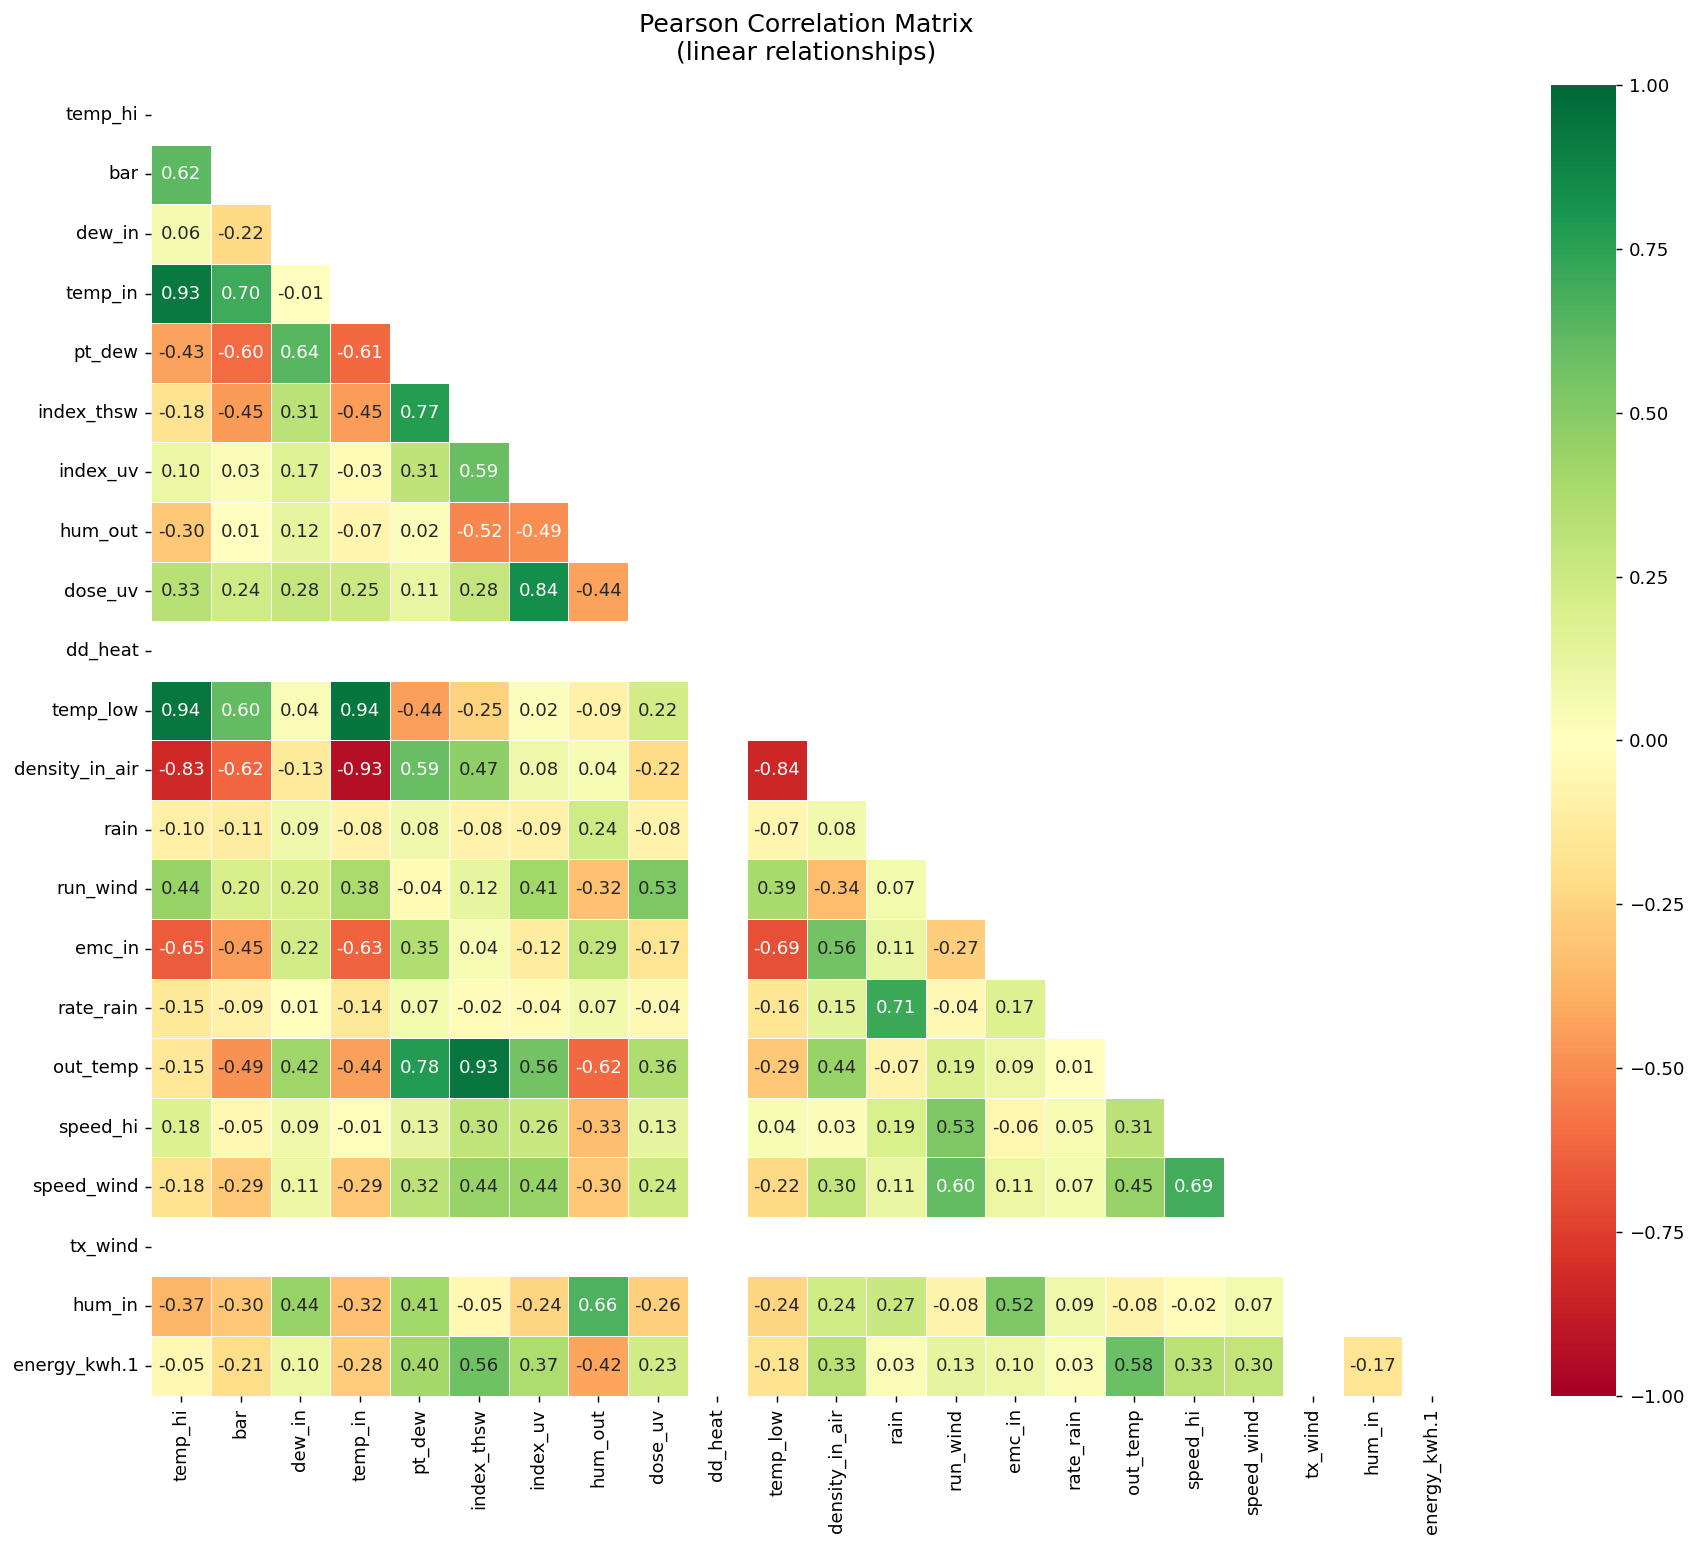


Pearson Correlations with Energy (ranked by |r|):
out_temp          0.5817
index_thsw        0.5648
hum_out          -0.4238
pt_dew            0.4007
index_uv          0.3715
speed_hi          0.3270
density_in_air    0.3263
speed_wind        0.2953
temp_in          -0.2774
dose_uv           0.2302
bar              -0.2093
temp_low         -0.1787
hum_in           -0.1659
run_wind          0.1274
dew_in            0.1038
emc_in            0.0990
temp_hi          -0.0514
rain              0.0330
rate_rain         0.0314
dd_heat              NaN
tx_wind              NaN


In [3]:
pearson_matrix = analysis_df.corr(method='pearson')

fig, ax = plt.subplots(figsize=(15, 12))
mask = np.triu(np.ones_like(pearson_matrix, dtype=bool))  # show lower triangle only

sns.heatmap(
    pearson_matrix,
    mask=mask,
    annot=True, fmt='.2f',
    cmap='RdYlGn', center=0,
    vmin=-1, vmax=1,
    linewidths=0.4,
    square=True,
    ax=ax
)
ax.set_title('Pearson Correlation Matrix\n(linear relationships)', fontsize=14, pad=14)
plt.tight_layout()
plt.savefig('../outputs/figures/pearson_heatmap.png', bbox_inches='tight')
plt.show()

# Ranked list: weather vars vs energy
pearson_vs_energy = pearson_matrix[TARGET].drop(TARGET)
print('\nPearson Correlations with Energy (ranked by |r|):')
print(
    pearson_vs_energy
    .reindex(pearson_vs_energy.abs().sort_values(ascending=False).index)
    .round(4)
    .to_string()
)

---
## STEP 2 — Spearman Correlation Heatmap
Measures **monotonic** (rank-based) correlation — better for skewed variables like rain, UV dose, wind.  
Formula: $r_s = 1 - \dfrac{6\sum d_i^2}{n(n^2-1)}$ where $d_i$ = rank difference

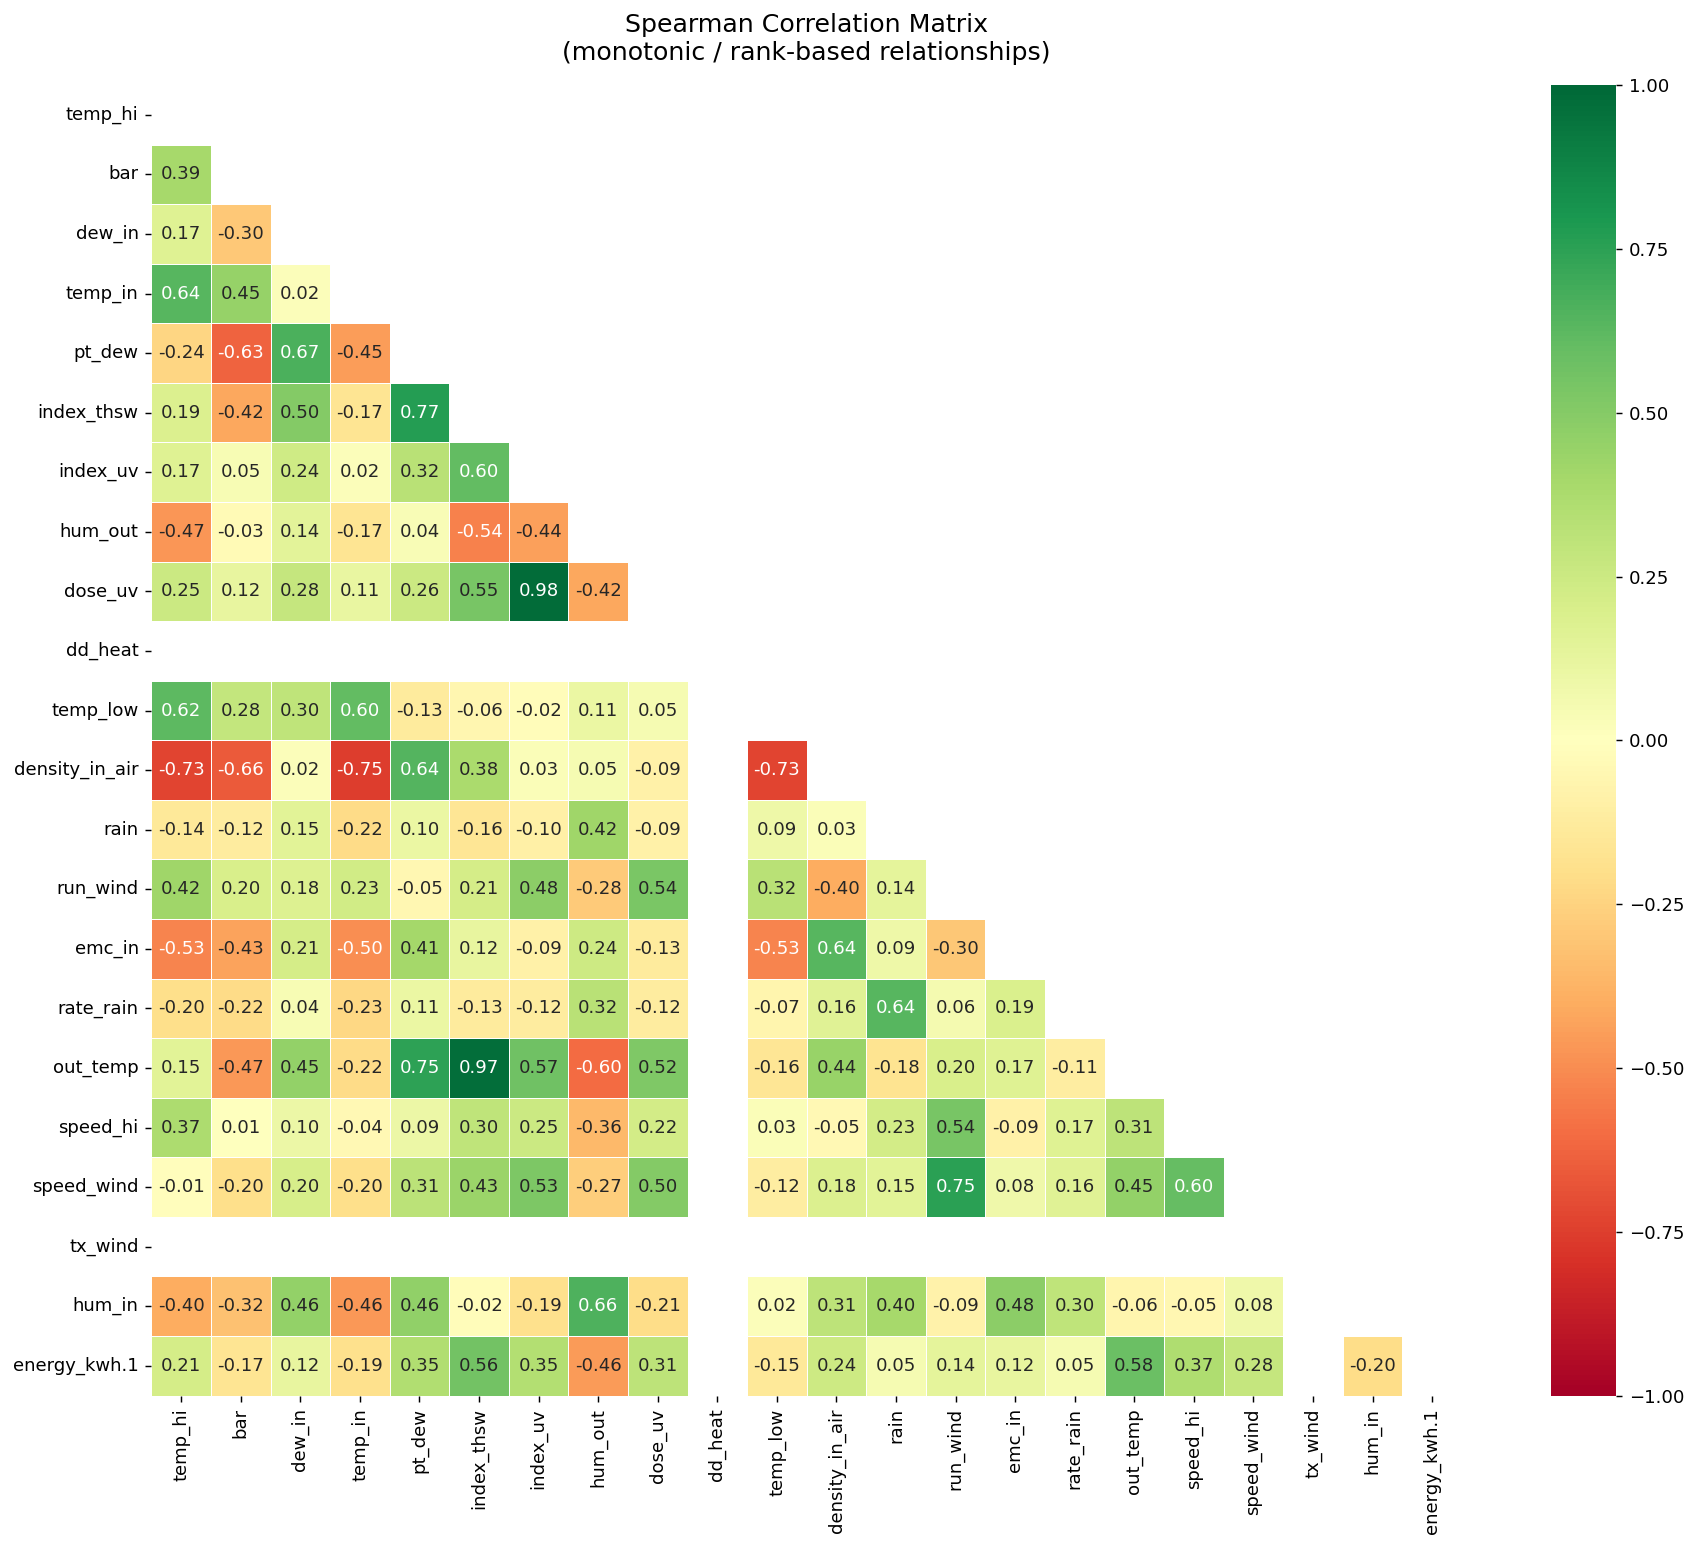


Spearman Correlations with Energy (ranked by |r|):
out_temp          0.5836
index_thsw        0.5603
hum_out          -0.4601
speed_hi          0.3651
pt_dew            0.3520
index_uv          0.3496
dose_uv           0.3116
speed_wind        0.2785
density_in_air    0.2436
temp_hi           0.2113
hum_in           -0.2050
temp_in          -0.1925
bar              -0.1658
temp_low         -0.1463
run_wind          0.1402
dew_in            0.1180
emc_in            0.1175
rain              0.0508
rate_rain         0.0504
dd_heat              NaN
tx_wind              NaN


In [4]:
spearman_matrix = analysis_df.corr(method='spearman')

fig, ax = plt.subplots(figsize=(15, 12))
mask = np.triu(np.ones_like(spearman_matrix, dtype=bool))

sns.heatmap(
    spearman_matrix,
    mask=mask,
    annot=True, fmt='.2f',
    cmap='RdYlGn', center=0,
    vmin=-1, vmax=1,
    linewidths=0.4,
    square=True,
    ax=ax
)
ax.set_title('Spearman Correlation Matrix\n(monotonic / rank-based relationships)', fontsize=14, pad=14)
plt.tight_layout()
plt.savefig('../outputs/figures/spearman_heatmap.png', bbox_inches='tight')
plt.show()

spearman_vs_energy = spearman_matrix[TARGET].drop(TARGET)
print('\nSpearman Correlations with Energy (ranked by |r|):')
print(
    spearman_vs_energy
    .reindex(spearman_vs_energy.abs().sort_values(ascending=False).index)
    .round(4)
    .to_string()
)

---
## STEP 3 — Pearson vs Spearman Bar Chart
Side-by-side comparison per variable vs energy.  
**Large gap (Δ > 0.1)** between Pearson and Spearman = nonlinear relationship exists.

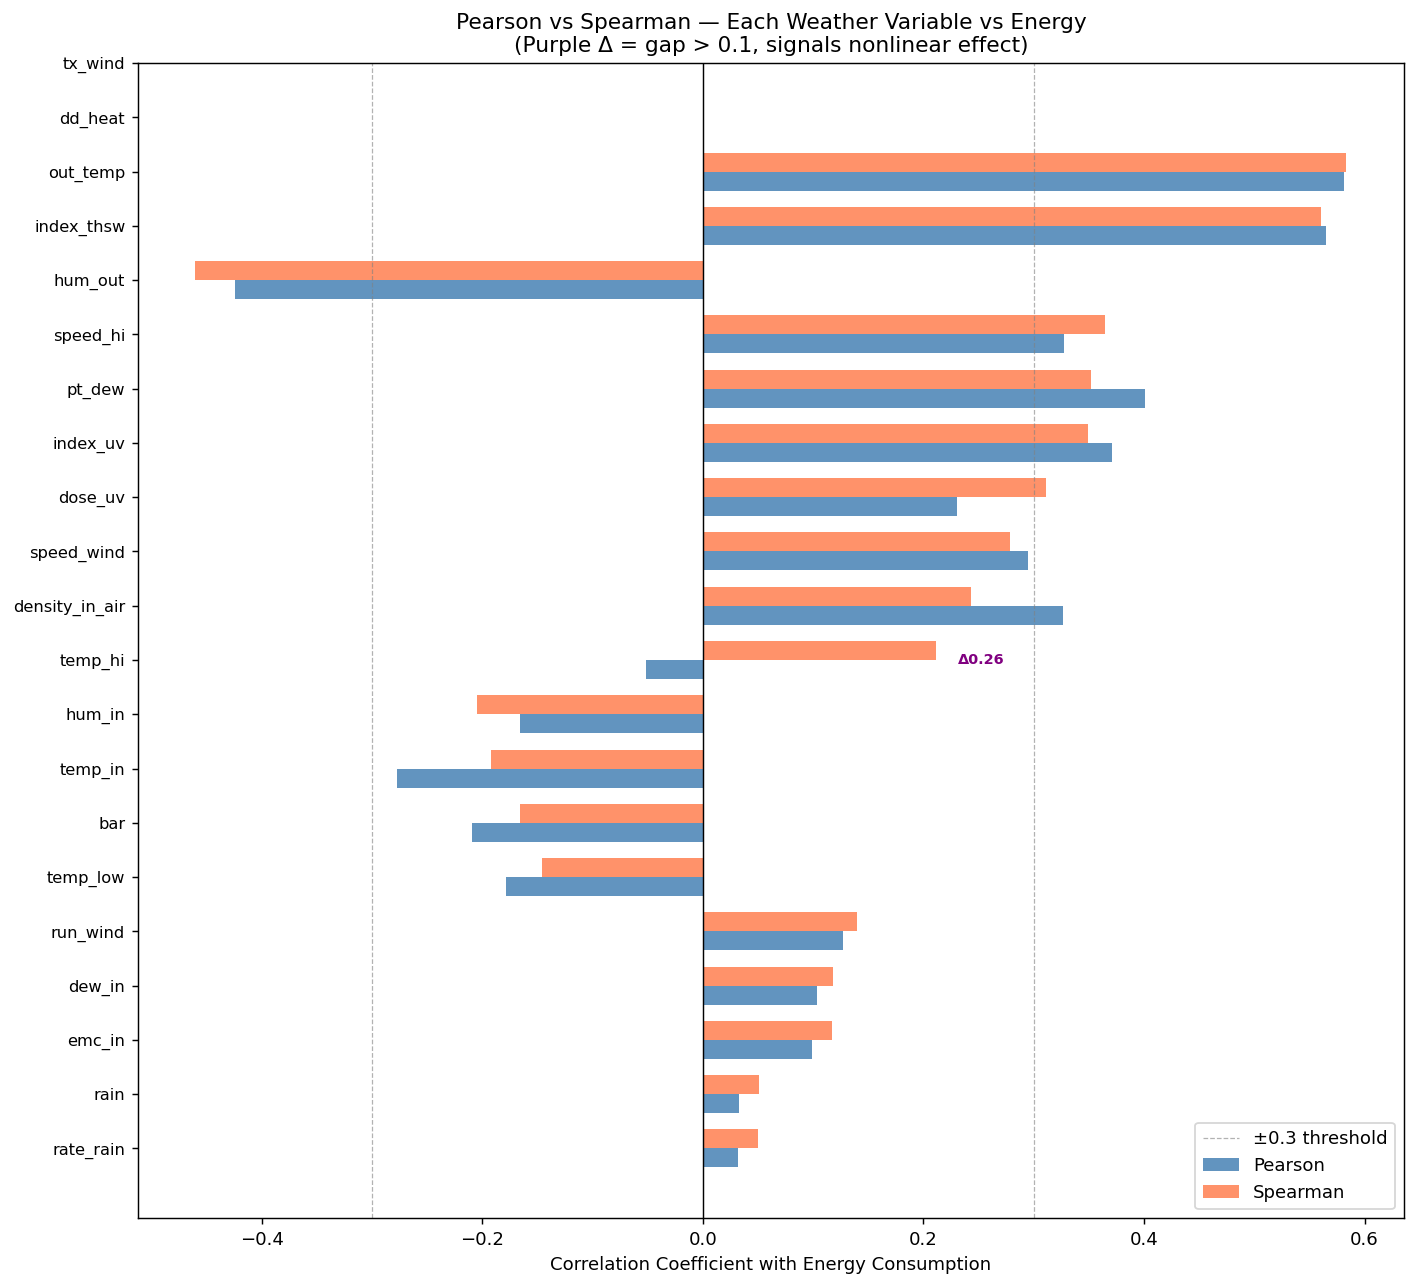

Pearson vs Spearman — Ranked by Gap (nonlinear candidates at top):
       Feature  Pearson_r  Spearman_r  Gap |P-S|
       temp_hi    -0.0514      0.2113     0.2626
       temp_in    -0.2774     -0.1925     0.0849
density_in_air     0.3263      0.2436     0.0827
       dose_uv     0.2302      0.3116     0.0814
        pt_dew     0.4007      0.3520     0.0486
           bar    -0.2093     -0.1658     0.0435
        hum_in    -0.1659     -0.2050     0.0391
      speed_hi     0.3270      0.3651     0.0381
       hum_out    -0.4238     -0.4601     0.0363
      temp_low    -0.1787     -0.1463     0.0324
      index_uv     0.3715      0.3496     0.0218
     rate_rain     0.0314      0.0504     0.0190
        emc_in     0.0990      0.1175     0.0186
          rain     0.0330      0.0508     0.0179
    speed_wind     0.2953      0.2785     0.0168
        dew_in     0.1038      0.1180     0.0142
      run_wind     0.1274      0.1402     0.0128
    index_thsw     0.5648      0.5603     0.0045
  

In [5]:
# Sort by absolute Spearman value (ascending for horizontal bar)
sort_order      = spearman_vs_energy.abs().sort_values(ascending=True).index
pearson_sorted  = pearson_vs_energy.loc[sort_order]
spearman_sorted = spearman_vs_energy.loc[sort_order]

y_pos  = np.arange(len(sort_order))
height = 0.35

fig, ax = plt.subplots(figsize=(11, 10))

ax.barh(y_pos - height/2, pearson_sorted.values,  height,
        color='steelblue', alpha=0.85, label='Pearson')
ax.barh(y_pos + height/2, spearman_sorted.values, height,
        color='coral',     alpha=0.85, label='Spearman')

ax.set_yticks(y_pos)
ax.set_yticklabels(sort_order, fontsize=9)
ax.axvline(0,    color='black', linewidth=0.8)
ax.axvline( 0.3, color='gray',  linewidth=0.7, linestyle='--', alpha=0.6, label='±0.3 threshold')
ax.axvline(-0.3, color='gray',  linewidth=0.7, linestyle='--', alpha=0.6)
ax.set_xlabel('Correlation Coefficient with Energy Consumption')
ax.set_title('Pearson vs Spearman — Each Weather Variable vs Energy\n'
             '(Purple Δ = gap > 0.1, signals nonlinear effect)', fontsize=12)
ax.legend(loc='lower right')

# Annotate large gaps
for i, feat in enumerate(sort_order):
    gap = abs(spearman_sorted[feat] - pearson_sorted[feat])
    if gap > 0.1:
        x_anchor = max(abs(spearman_sorted[feat]), abs(pearson_sorted[feat])) + 0.02
        ax.text(x_anchor, i, f'Δ{gap:.2f}', va='center', fontsize=8, color='purple', fontweight='bold')

plt.tight_layout()
plt.savefig('../outputs/figures/pearson_vs_spearman_bar.png', bbox_inches='tight')
plt.show()

# Summary comparison table
comparison_df = (
    pd.DataFrame({
        'Feature'    : sort_order,
        'Pearson_r'  : pearson_vs_energy.loc[sort_order].values.round(4),
        'Spearman_r' : spearman_vs_energy.loc[sort_order].values.round(4),
        'Gap |P-S|'  : (pearson_vs_energy.loc[sort_order] -
                        spearman_vs_energy.loc[sort_order]).abs().values.round(4)
    })
    .sort_values('Gap |P-S|', ascending=False)
    .reset_index(drop=True)
)

print('Pearson vs Spearman — Ranked by Gap (nonlinear candidates at top):')
print(comparison_df.to_string(index=False))

---
## STEP 4 — Scatter Plots for Top 6 Variables
Visual confirmation of relationship shape with OLS regression line and r / p-value.

Top 6 features by |Spearman| vs energy: ['out_temp', 'index_thsw', 'hum_out', 'speed_hi', 'pt_dew', 'index_uv']


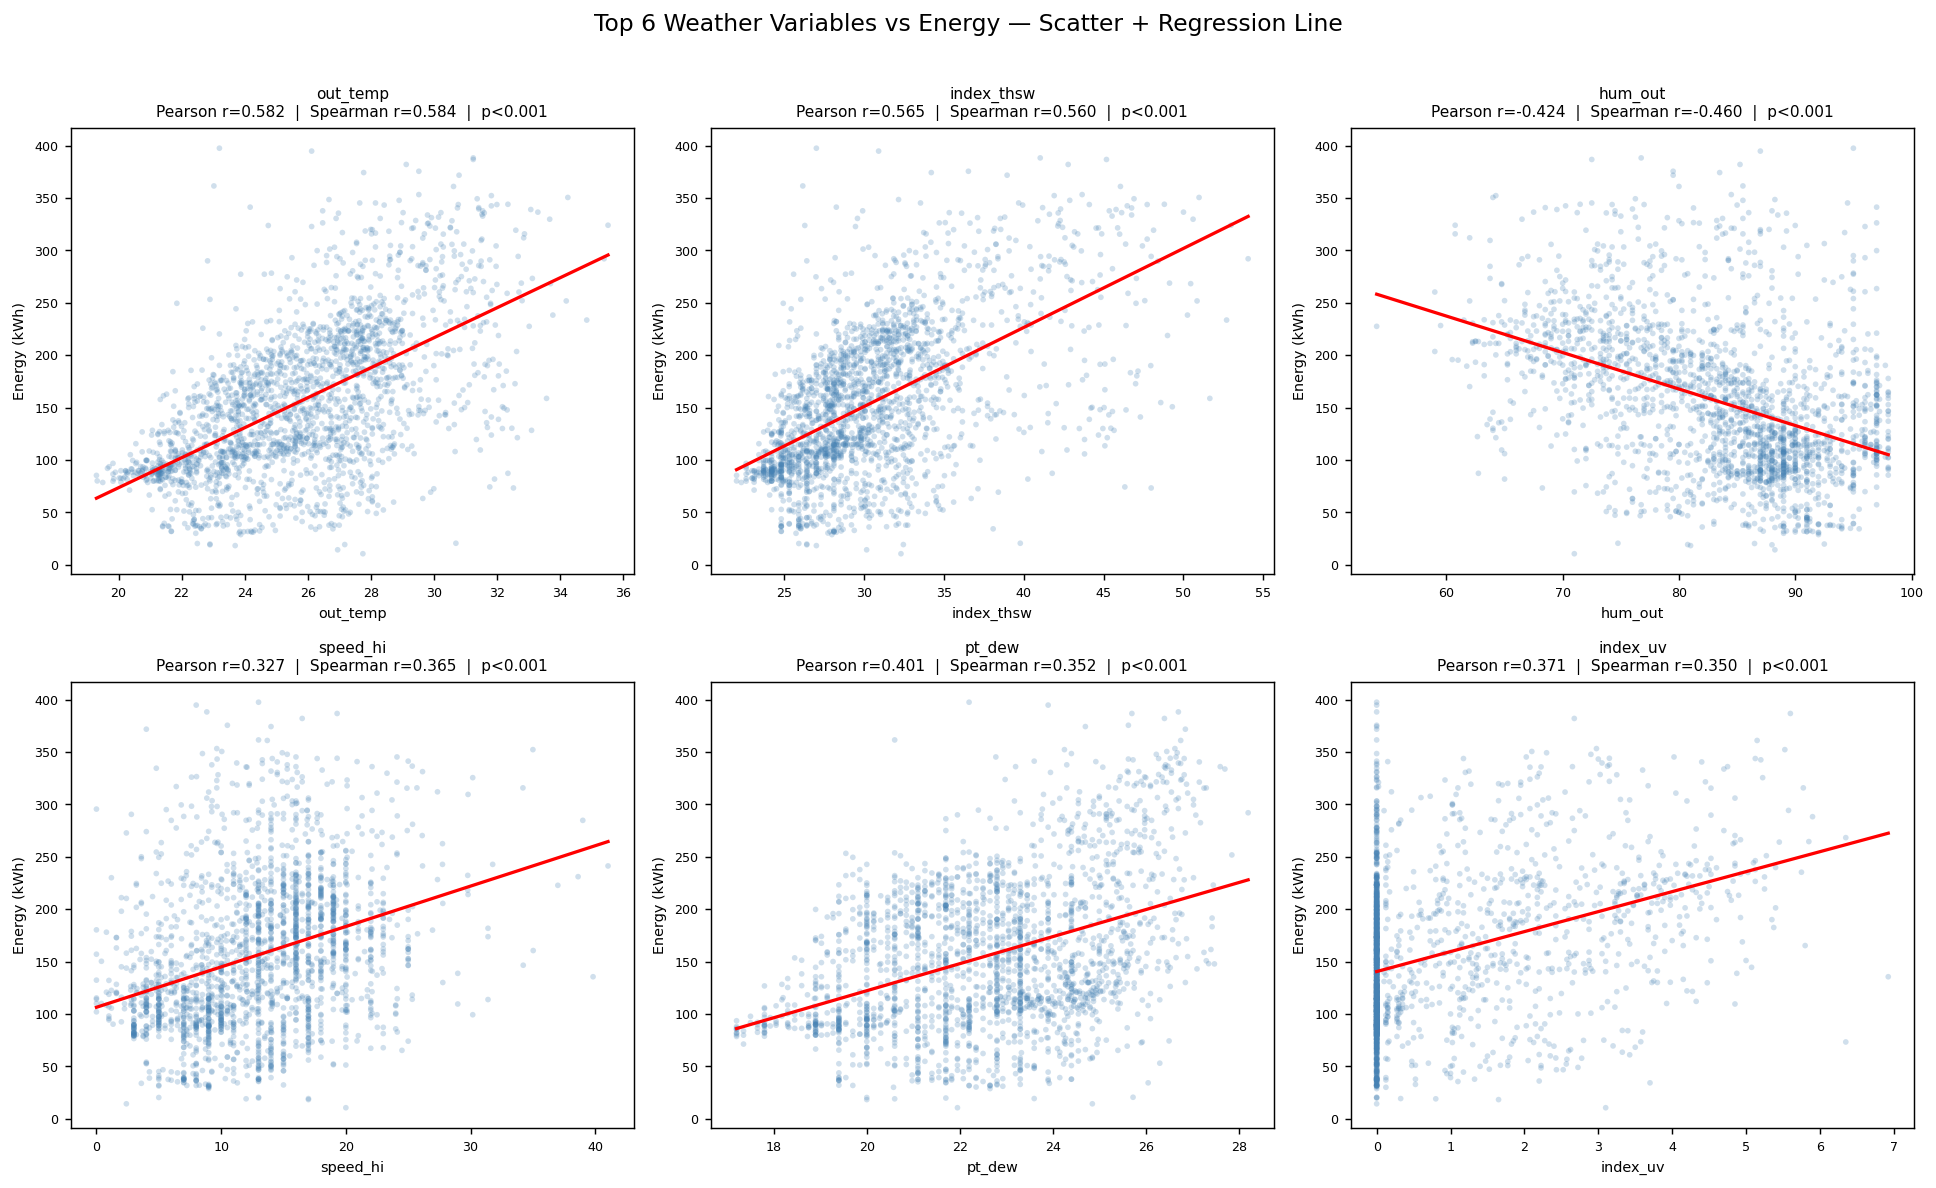

In [6]:
top6 = spearman_vs_energy.abs().sort_values(ascending=False).head(6).index.tolist()
print('Top 6 features by |Spearman| vs energy:', top6)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, feat in enumerate(top6):
    ax  = axes[i]
    x   = analysis_df[feat].values
    y   = analysis_df[TARGET].values

    ax.scatter(x, y, alpha=0.25, s=10, color='steelblue', edgecolors='none')

    # OLS regression line
    slope, intercept, r_val, p_val, _ = stats.linregress(x, y)
    x_line = np.linspace(x.min(), x.max(), 200)
    ax.plot(x_line, slope * x_line + intercept, color='red', linewidth=1.8)

    p_label = 'p<0.001' if p_val < 0.001 else f'p={p_val:.3f}'
    spear_r = spearman_vs_energy[feat]
    ax.set_title(
        f'{feat}\nPearson r={r_val:.3f}  |  Spearman r={spear_r:.3f}  |  {p_label}',
        fontsize=8.5
    )
    ax.set_xlabel(feat, fontsize=8)
    ax.set_ylabel('Energy (kWh)', fontsize=8)
    ax.tick_params(labelsize=7)

plt.suptitle('Top 6 Weather Variables vs Energy — Scatter + Regression Line',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('../outputs/figures/scatter_top6.png', bbox_inches='tight')
plt.show()

---
## STEP 5 — Interaction Terms (Cross-Variable Effects on Energy)
Creates all pairwise products: `feat_A × feat_B`.  
Correlates each product with energy — tells you which **combination** of variables drives energy the most.

In [7]:
interaction_records = []

for feat_a, feat_b in combinations(feature_cols, 2):
    interaction = analysis_df[feat_a] * analysis_df[feat_b]

    if interaction.std() == 0:   # skip constant (zero-variance) interactions
        continue

    p_r, p_p = stats.pearsonr(interaction,  analysis_df[TARGET])
    s_r, s_p = stats.spearmanr(interaction, analysis_df[TARGET])

    interaction_records.append({
        'Interaction' : f'{feat_a}  ×  {feat_b}',
        'Pearson_r'   : round(p_r, 4),
        'Pearson_p'   : round(p_p, 4),
        'Spearman_r'  : round(s_r, 4),
        'Spearman_p'  : round(s_p, 4),
        'Abs_Spearman': abs(round(s_r, 4))
    })

interaction_df = (
    pd.DataFrame(interaction_records)
    .sort_values('Abs_Spearman', ascending=False)
    .reset_index(drop=True)
)

print(f'Total pairwise interaction terms : {len(interaction_df)}')
print('\nTop 20 Cross-Variable Effects on Energy:')
print(interaction_df.drop(columns='Abs_Spearman').head(20).to_string(index=False))

Total pairwise interaction terms : 190

Top 20 Cross-Variable Effects on Energy:
                  Interaction  Pearson_r  Pearson_p  Spearman_r  Spearman_p
             bar  ×  out_temp     0.5839        0.0      0.5872         0.0
  density_in_air  ×  out_temp     0.5860        0.0      0.5842         0.0
         out_temp  ×  tx_wind     0.5817        0.0      0.5836         0.0
      index_thsw  ×  out_temp     0.5733        0.0      0.5738         0.0
index_thsw  ×  density_in_air     0.5664        0.0      0.5630         0.0
           bar  ×  index_thsw     0.5660        0.0      0.5627         0.0
       index_thsw  ×  tx_wind     0.5648        0.0      0.5603         0.0
        index_thsw  ×  emc_in     0.5294        0.0      0.5398         0.0
          emc_in  ×  out_temp     0.4861        0.0      0.5236         0.0
          temp_in  ×  hum_out    -0.4590        0.0     -0.4994         0.0
          pt_dew  ×  out_temp     0.5311        0.0      0.4963         0.0
       

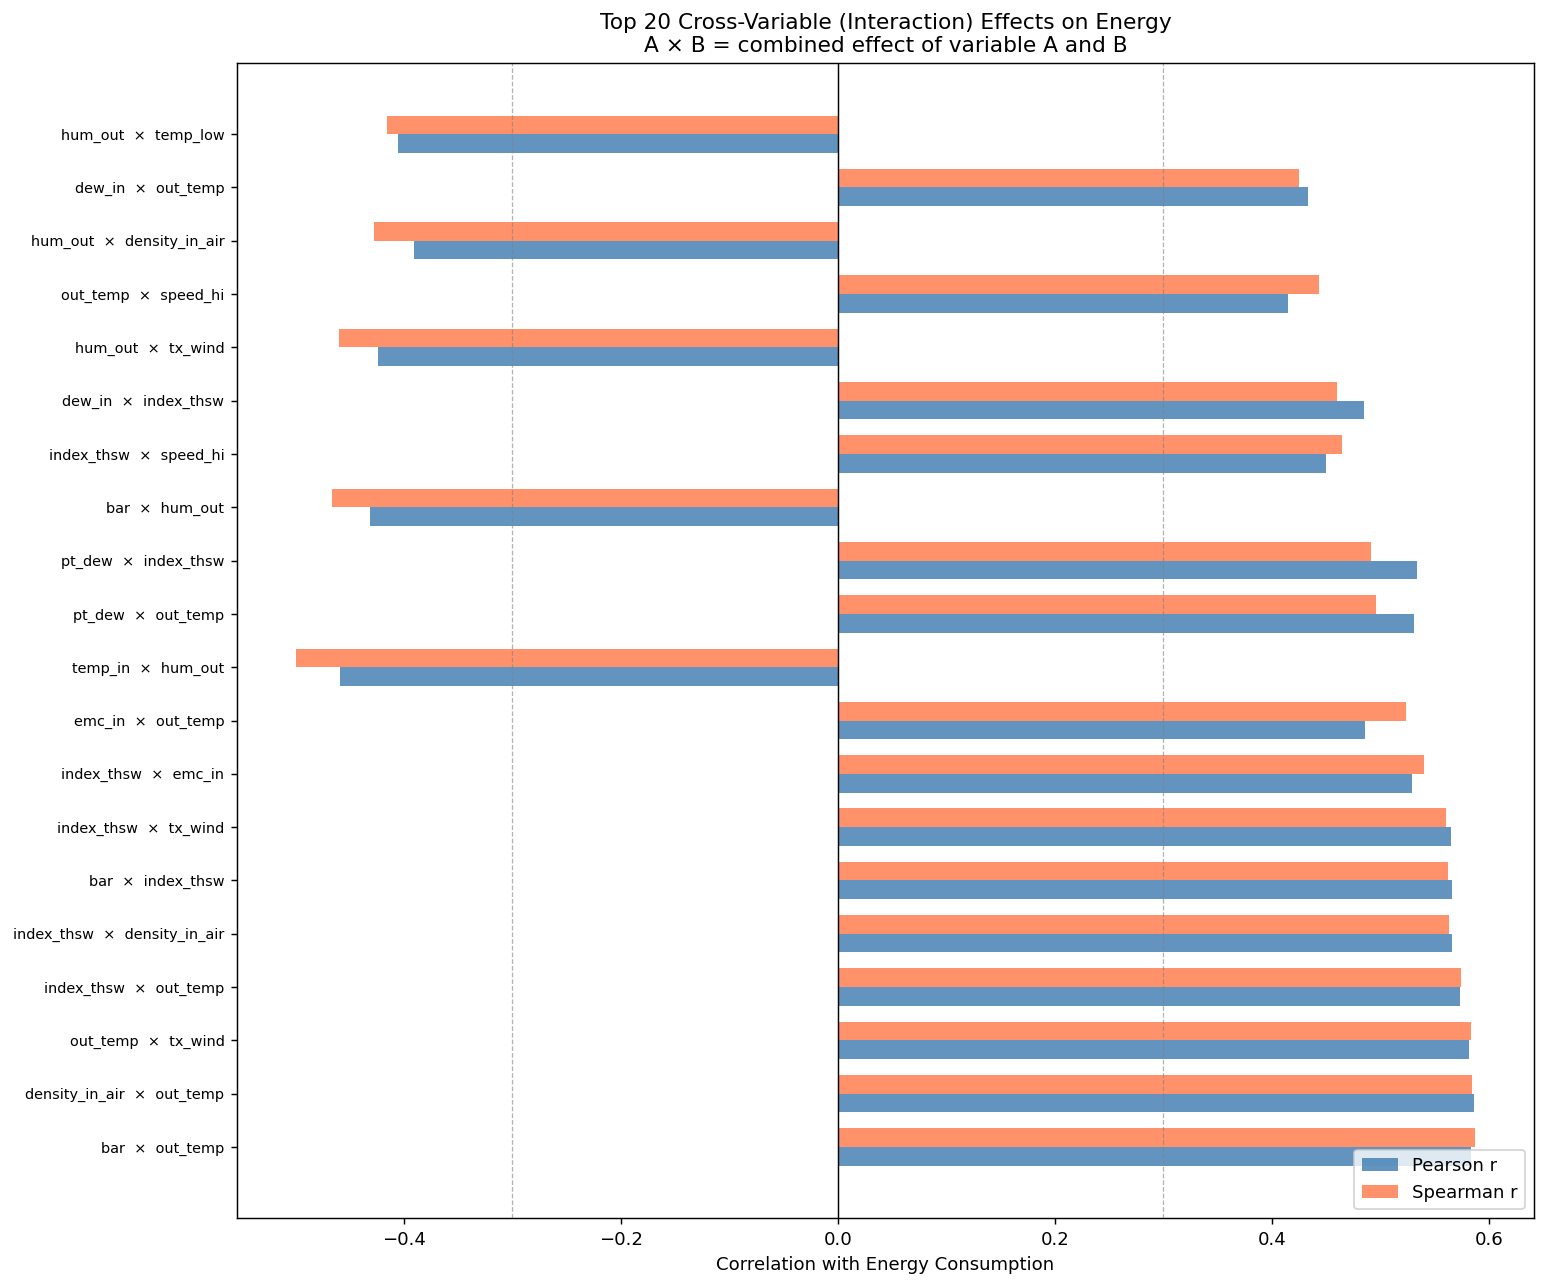

In [8]:
# Plot top 20 interaction terms
top20  = interaction_df.head(20).copy()
y_pos  = np.arange(len(top20))
height = 0.35

fig, ax = plt.subplots(figsize=(12, 10))

ax.barh(y_pos - height/2, top20['Pearson_r'].values,  height,
        color='steelblue', alpha=0.85, label='Pearson r')
ax.barh(y_pos + height/2, top20['Spearman_r'].values, height,
        color='coral',     alpha=0.85, label='Spearman r')

ax.set_yticks(y_pos)
ax.set_yticklabels(top20['Interaction'], fontsize=8)
ax.axvline(0,    color='black', linewidth=0.8)
ax.axvline( 0.3, color='gray',  linewidth=0.7, linestyle='--', alpha=0.6)
ax.axvline(-0.3, color='gray',  linewidth=0.7, linestyle='--', alpha=0.6)
ax.set_xlabel('Correlation with Energy Consumption')
ax.set_title('Top 20 Cross-Variable (Interaction) Effects on Energy\n'
             'A × B = combined effect of variable A and B', fontsize=12)
ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig('../outputs/figures/interaction_terms_bar.png', bbox_inches='tight')
plt.show()

In [9]:
# =============================================================================
# FINAL SUMMARY — Individual + Top 10 Interactions ranked together
# =============================================================================
individual_summary = pd.DataFrame({
    'Variable'    : feature_cols,
    'Type'        : 'Individual',
    'Pearson_r'   : pearson_vs_energy.loc[feature_cols].values.round(4),
    'Spearman_r'  : spearman_vs_energy.loc[feature_cols].values.round(4),
    'Abs_Spearman': spearman_vs_energy.loc[feature_cols].abs().values.round(4)
})

top10_interactions = pd.DataFrame({
    'Variable'    : interaction_df['Interaction'].head(10).values,
    'Type'        : 'Interaction',
    'Pearson_r'   : interaction_df['Pearson_r'].head(10).values,
    'Spearman_r'  : interaction_df['Spearman_r'].head(10).values,
    'Abs_Spearman': interaction_df['Abs_Spearman'].head(10).values
})

final_summary = (
    pd.concat([individual_summary, top10_interactions], ignore_index=True)
    .sort_values('Abs_Spearman', ascending=False)
    .drop(columns='Abs_Spearman')
    .reset_index(drop=True)
)

print('=' * 78)
print('FINAL RANKING — Individual Variables + Top 10 Interactions vs Energy')
print('=' * 78)
print(final_summary.to_string(index=False))

# Export
final_summary.to_csv('../outputs/tables/correlation_summary.csv', index=False)
interaction_df.drop(columns='Abs_Spearman').to_csv('../outputs/tables/all_interaction_correlations.csv', index=False)
print('\nSaved: correlation_summary.csv  |  all_interaction_correlations.csv')

FINAL RANKING — Individual Variables + Top 10 Interactions vs Energy
                     Variable        Type  Pearson_r  Spearman_r
             bar  ×  out_temp Interaction     0.5839      0.5872
  density_in_air  ×  out_temp Interaction     0.5860      0.5842
                     out_temp  Individual     0.5817      0.5836
         out_temp  ×  tx_wind Interaction     0.5817      0.5836
      index_thsw  ×  out_temp Interaction     0.5733      0.5738
index_thsw  ×  density_in_air Interaction     0.5664      0.5630
           bar  ×  index_thsw Interaction     0.5660      0.5627
       index_thsw  ×  tx_wind Interaction     0.5648      0.5603
                   index_thsw  Individual     0.5648      0.5603
        index_thsw  ×  emc_in Interaction     0.5294      0.5398
          emc_in  ×  out_temp Interaction     0.4861      0.5236
          temp_in  ×  hum_out Interaction    -0.4590     -0.4994
                      hum_out  Individual    -0.4238     -0.4601
                     